# Consider a very back of the envelope scenario to check how transverse galactic accerlation compares with the SGWB


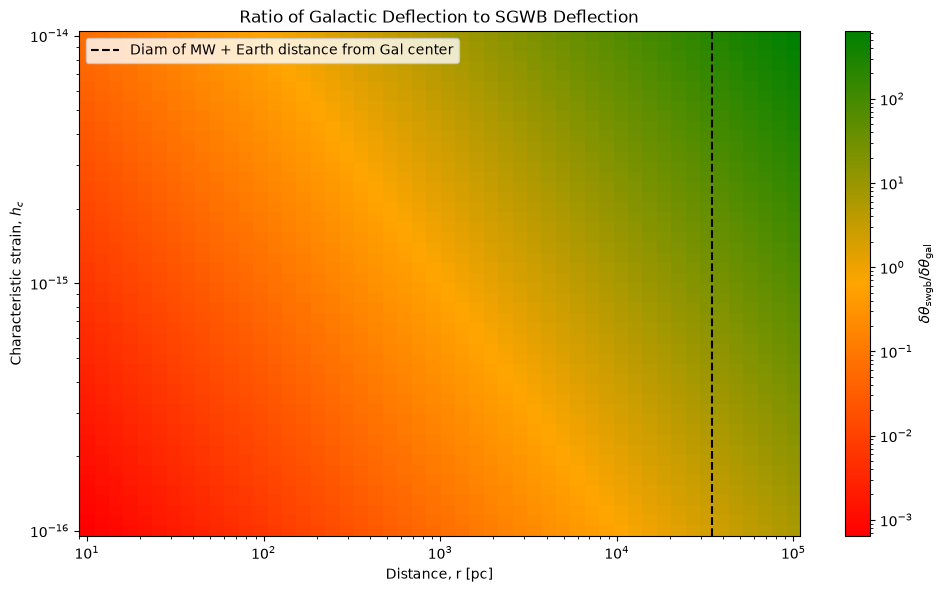

In [19]:
import numpy as np
import matplotlib.pyplot as plt

def delta_theta_gal_res(a_tranv, r, baseline_yrs):
    # assumes a_tranv is in m/s^2, r in pc, and baseline_yrs in yr
    m_per_sec_sqrd_2_pc_per_yrs_sqrd = 3.0856776e-16 / (3.15576e-7)**2
    radiants_2_nas_factor = (206264806247.1)**(1)
    a_tranv = m_per_sec_sqrd_2_pc_per_yrs_sqrd * a_tranv
    return ((1/12) * (a_tranv / r) * baseline_yrs ** 2) * radiants_2_nas_factor

def delta_theta_swgb(h_c, baseline_yrs):
    # the deflection due to the SWGB is approximately delta Theta =  T R h_C
    # R (geometric factor) is order unity 
    # T (transfer function) is order unity

    radiants_2_nas_factor = (206264806247.1)**(1)
    return (h_c) * radiants_2_nas_factor


baseline_yrs = 5.5
h_c = np.logspace(-14, -16, 50)
r = np.logspace(1, 5, 50)
a_tranv  = 2e-10 #m/s^2 roughly how our solar system is accerlating around through milkyway
# Ratio: galactic transverse acceleration deflection / SGWB deflection
ratio = (
    delta_theta_swgb(h_c[:, None], baseline_yrs) / delta_theta_gal_res(a_tranv, r[None, :], baseline_yrs)
)

# Red -> amber -> green, with logarithmic color scaling
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "red_amber_green",
    ["red", "orange", "green"]
)
norm = plt.matplotlib.colors.LogNorm(
    vmin=np.nanmin(ratio),
    vmax=np.nanmax(ratio)
)

fig, ax = plt.subplots(figsize=(10, 6))

mesh = ax.pcolormesh(
    r,
    h_c,
    ratio,
    cmap=cmap,
    norm=norm,
    shading="auto"
)
d = 7665.0348 + 26800

mesh.set_cmap(cmap)


ax.axvline(
    d,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Diam of MW + Earth distance from Gal center"
)
ax.legend()
ax.set_yscale("log")
ax.set_xlabel("Distance, r [pc]")
ax.set_ylabel(r"Characteristic strain, $h_c$")
ax.set_title("Ratio of Galactic Deflection to SGWB Deflection")

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label(r"$\delta\theta_{\rm swgb}/\delta\theta_{\rm gal}$")

plt.tight_layout()
# plt.show()

ax.set_xscale("log")
ax.set_yscale("log")

fig.canvas.draw()
plt.show()


# With a more realistic gal accerlation curve

Assumsions of the gallactic accerlation curve
- Consider 3 components to the velocity curve (v^2) value: bulge, flat-disk, dark matter halo.

Summary
- Considering the relative accerlation of our solar system with the stars accerlation due to galactic accerlation reduces the amplitude of the approximate residual by an order of magnitude at its minimum.
- Due to considering the relative accerlation + the extra assumptions for the velocity curve, allows for the SWGB at lower characteristic strains to still have a larger contribution relative to the galactic accerlation


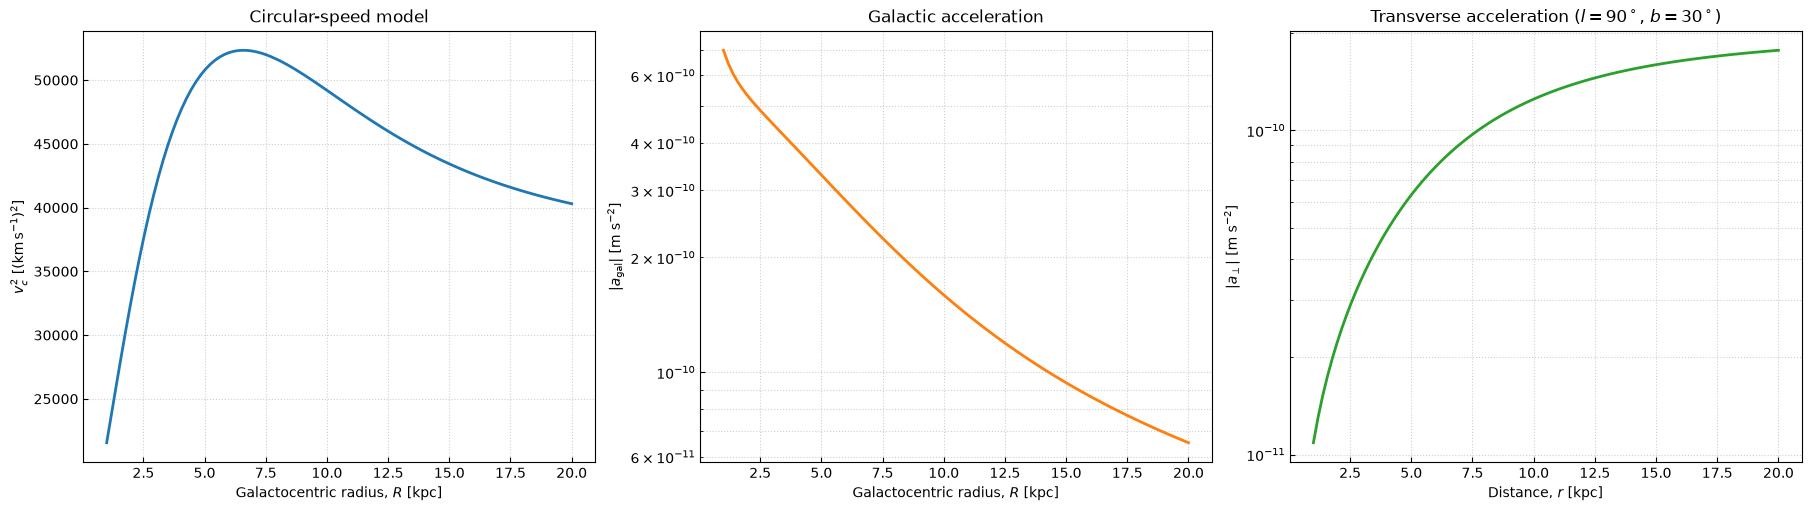

3.2564676125092615e-06
2.062648062471e-07


/tmp/ipykernel_1636/3788024215.py:176: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


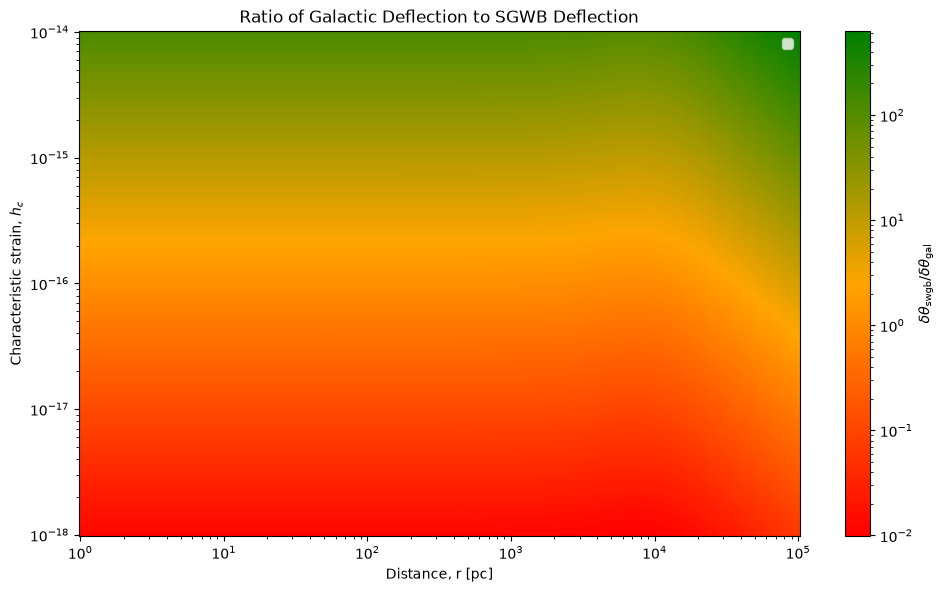

In [51]:
KPC = 3.085677581491367e19       # m
YEAR = 365.25 * 86400.0          # s
RAD_TO_NAS = 206264806247.09636  # nanoarcsec/radian
G = 4.30091e-6                  # kpc (km/s)^2 / Msun

from scipy.special import iv, kv

def vc2_realistic(R_kpc):
    """Representative Milky-Way v_c(R)^2 in (km/s)^2.

    Components: Hernquist bulge, exponential stellar disk, and NFW halo.
    These parameters are useful for estimates, not precision mass modelling.
    """
    R = np.maximum(np.asarray(R_kpc, dtype=float), 1e-8)

    # Hernquist bulge
    M_bulge, a_bulge = 5.0e9, 0.50
    v2_bulge = G * M_bulge * R / (R + a_bulge) ** 2

    # Freeman exponential disk
    M_disk, R_disk = 5.5e10, 2.6
    sigma0 = M_disk / (2.0 * np.pi * R_disk**2)
    y = R / (2.0 * R_disk)
    bessel_term = iv(0, y) * kv(0, y) - iv(1, y) * kv(1, y)
    v2_disk = 4.0 * np.pi * G * sigma0 * R_disk * y**2 * bessel_term

    # NFW halo
    M200, R200, concentration = 1.0e12, 210.0, 10.0
    rs = R200 / concentration
    x = R / rs
    f = np.log1p(x) - x / (1.0 + x)
    fc = np.log1p(concentration) - concentration / (1.0 + concentration)
    v2_halo = G * M200 / R * f / fc

    return v2_bulge + v2_disk + v2_halo


def heliocentric_unit_vector(l_deg, b_deg):
    """Unit vector from Sun to (l,b); x points from Galactic centre to Sun."""
    l, b = np.deg2rad(l_deg), np.deg2rad(b_deg)
    return np.array([-np.cos(b) * np.cos(l),
                      np.cos(b) * np.sin(l), np.sin(b)])


def galactic_acceleration(pos_kpc):
    """Axisymmetric planar acceleration at Galactocentric positions, in m/s^2."""
    pos = np.asarray(pos_kpc, dtype=float)
    R = np.hypot(pos[..., 0], pos[..., 1])
    R_safe = np.maximum(R, 1e-8)
    # (km/s)^2/kpc -> m/s^2
    a_mag = vc2_realistic(R_safe) / R_safe * 1.0e6 / KPC
    acc = np.zeros_like(pos)
    acc[..., 0] = -a_mag * pos[..., 0] / R_safe
    acc[..., 1] = -a_mag * pos[..., 1] / R_safe
    return acc


def transverse_acceleration(l_deg, b_deg, distance_kpc, R0_kpc=8.2):
    """Relative star-minus-Sun transverse acceleration in m/s^2."""
    n = heliocentric_unit_vector(l_deg, b_deg)
    d = np.asarray(distance_kpc, dtype=float)
    sun_pos = np.array([R0_kpc, 0.0, 0.0])
    star_pos = sun_pos + d[..., None] * n
    a_rel = galactic_acceleration(star_pos) - galactic_acceleration(sun_pos)
    a_los = np.sum(a_rel * n, axis=-1, keepdims=True) * n
    return np.linalg.norm(a_rel - a_los, axis=-1)


R_kpc = np.linspace(1,20,100)

# Evaluate the acceleration along the Galactic x-axis
positions = np.column_stack((R_kpc, np.zeros_like(R_kpc), np.zeros_like(R_kpc)))
a_galactic = np.linalg.norm(galactic_acceleration(positions), axis=-1)
a_transverse = transverse_acceleration(90.0, 30.0, R_kpc)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

# Circular velocity squared
axes[0].plot(R_kpc, vc2_realistic(R_kpc), color="tab:blue", linewidth=2)
axes[0].set_xlabel(r"Galactocentric radius, $R$ [kpc]")
axes[0].set_ylabel(r"$v_c^2$ [$(\mathrm{km\,s^{-1}})^2$]")
axes[0].set_title("Circular-speed model")

# Total Galactic acceleration
axes[1].plot(R_kpc, a_galactic, color="tab:orange", linewidth=2)
axes[1].set_xlabel(r"Galactocentric radius, $R$ [kpc]")
axes[1].set_ylabel(r"$|a_{\mathrm{gal}}|$ [m s$^{-2}$]")
axes[1].set_title("Galactic acceleration")
axes[1].set_yscale("log")

# Transverse acceleration
axes[2].plot(R_kpc, a_transverse, color="tab:green", linewidth=2)
axes[2].set_xlabel(r"Distance, $r$ [kpc]")
axes[2].set_ylabel(r"$|a_\perp|$ [m s$^{-2}$]")
axes[2].set_title(r"Transverse acceleration ($l=90^\circ$, $b=30^\circ$)")
axes[2].set_yscale("log")

for ax in axes:
    ax.grid(True, which="both", linestyle=":", alpha=0.6)
    ax.tick_params(direction="in", which="both")

plt.show()

h_c = np.logspace(-14, -18, 220)
distance_kpc = np.logspace(-3, 2, 220)  # 10 pc to 100 kpc
l_deg, b_deg = 90.0, 30               # change to your sightline
a_transverse = transverse_acceleration(l_deg, b_deg, distance_kpc)

# Match dimensions: 50 strain values × 220 distance values.
distance_pc = distance_kpc * 1_000.0

sgwb_deflection = delta_theta_swgb(
    h_c[:, None],
    baseline_yrs
)

galactic_deflection = delta_theta_gal_res(
    a_transverse[None, :],
    distance_pc[None, :],
    baseline_yrs
)

ratio = sgwb_deflection / galactic_deflection

# Use consistent units and explicit broadcasting.
# distance_kpc is used for the acceleration calculation; r is in pc.
distance_pc = distance_kpc * 1_000.0

a_grid = a_transverse[None, :]       # shape: (1, 220), m/s²
r_grid = distance_pc[None, :]        # shape: (1, 220), pc
h_grid = h_c[:, None]                # shape: (50, 1)

# Both functions return angular deflections in the same units.
sgwb_deflection = delta_theta_swgb(h_grid, baseline_yrs)
galactic_deflection = delta_theta_gal_res(
    a_grid,
    r_grid,
    baseline_yrs
)
print(np.min(galactic_deflection))
print(np.min(sgwb_deflection))

ratio = sgwb_deflection / galactic_deflection
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "red_amber_green",
    ["red", "orange", "green"]
)
norm = plt.matplotlib.colors.LogNorm(
    vmin=np.nanmin(ratio),
    vmax=np.nanmax(ratio)
)

fig, ax = plt.subplots(figsize=(10, 6))

mesh = ax.pcolormesh(
    distance_pc,   # 220 x-values
    h_c,           # 50 y-values
    ratio,         # shape (50, 220)
    cmap=cmap,
    norm=norm,
    shading="auto"
)


mesh.set_cmap(cmap)

# d = 7665.0348 + 26800
# ax.axvline(
#     d,
#     color="black",
#     linestyle="--",
#     linewidth=1.5,
#     label="Diam of MW + Earth distance from Gal center"
# )

ax.legend()
ax.set_yscale("log")
ax.set_xlabel("Distance, r [pc]")
ax.set_ylabel(r"Characteristic strain, $h_c$")
ax.set_title("Ratio of Galactic Deflection to SGWB Deflection")

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label(r"$\delta\theta_{\rm swgb}/\delta\theta_{\rm gal}$")

plt.tight_layout()
# plt.show()

ax.set_xscale("log")
ax.set_yscale("log")

fig.canvas.draw()
plt.show()


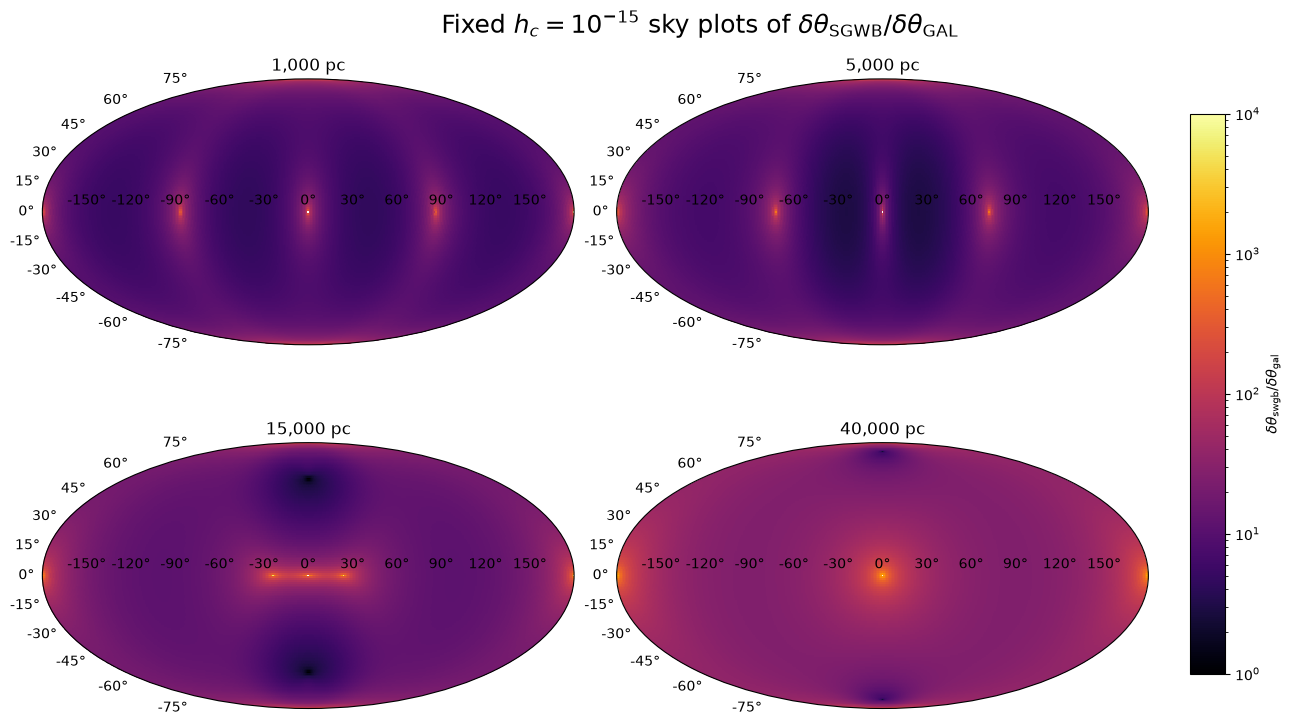

In [53]:
h_c_fixed = 1e-15
distances_pc = np.array([1_000, 5_000, 15_000, 40_000])

# Galactic-coordinate sky grid
l_vals = np.linspace(-180, 180, 361)
b_vals = np.linspace(-90, 90, 181)
l_grid, b_grid = np.meshgrid(l_vals, b_vals)

l_rad = np.deg2rad(l_grid)
b_rad = np.deg2rad(b_grid)

# Unit vectors from the Sun toward each sky position
n = np.stack(
    [
        -np.cos(b_rad) * np.cos(l_rad),
        np.cos(b_rad) * np.sin(l_rad),
        np.sin(b_rad),
    ],
    axis=-1,
)

sun_pos = np.array([8.2, 0.0, 0.0])
a_sun = galactic_acceleration(sun_pos)

ratios = []

for distance_pc_fixed in distances_pc:
    distance_kpc_fixed = distance_pc_fixed / 1_000.0
    star_pos = sun_pos + distance_kpc_fixed * n

    a_rel = galactic_acceleration(star_pos) - a_sun
    a_los = np.sum(a_rel * n, axis=-1, keepdims=True) * n
    a_trans = np.linalg.norm(a_rel - a_los, axis=-1)

    gal_deflection = delta_theta_gal_res(
        a_trans,
        distance_pc_fixed,
        baseline_yrs,
    )
    sgwb_deflection_fixed = delta_theta_swgb(
        h_c_fixed,
        baseline_yrs,
    )

    ratios.append(
        np.divide(
            sgwb_deflection_fixed,
            gal_deflection,
            out=np.full_like(gal_deflection, np.nan),
            where=gal_deflection > 0,
        )
    )

norm = plt.matplotlib.colors.LogNorm(
    vmin=1, #np.nanmin(ratios),
    vmax=1e4 #np.nanmax(ratios),
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 8),
    subplot_kw={"projection": "mollweide"},
)

for ax, distance_pc_fixed, ratio_sky in zip(
    axes.flat,
    distances_pc,
    ratios,
):
    mesh = ax.pcolormesh(
        np.deg2rad(l_grid),
        np.deg2rad(b_grid),
        ratio_sky,
        shading="auto",
        cmap="inferno",
        norm=norm,
    )

    if ax is axes.flat[0]:
        fig.subplots_adjust(
            left=0.03,
            right=0.82,
            bottom=0.08,
            top=0.92,
            wspace=0.08,
            hspace=0.18,
        )

        cbar_ax = fig.add_axes([0.85, 0.15, 0.025, 0.70])
        cbar = fig.colorbar(mesh, cax=cbar_ax)
        cbar.set_label(r"$\delta\theta_{\rm swgb}/\delta\theta_{\rm gal}$")
    ax.set_title(f"{distance_pc_fixed:,} pc")

    fig.suptitle(
        r"Fixed $h_c = 10^{-15}$ sky plots of $\delta\theta_{\rm SGWB} / \delta\theta_{\rm GAL}$",
        x=0.5,
        y=0.98,
        ha="center",
        fontsize=18,
    )
    # plt.show()